<a href="https://colab.research.google.com/github/farah-naz01/MRI-Physics-and-Reconstruction/blob/main/02_MRI_Signal_Formation/FID_and_Precession.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np

# Transverse magnetization at 45 degrees
phase_deg = 45
phase_rad = np.deg2rad(phase_deg)

Mx = np.cos(phase_rad)
My = np.sin(phase_rad)

# Complex transverse magnetization
M_complex = Mx + 1j * My

print("Mx:", Mx)
print("My:", My)
print("Complex magnetization:", M_complex)

# Magnitude and phase
print("Magnitude:", np.abs(M_complex))
print("Phase (degrees):", np.rad2deg(np.angle(M_complex)))

Mx: 0.7071067811865476
My: 0.7071067811865475
Complex magnetization: (0.7071067811865476+0.7071067811865475j)
Magnitude: 1.0
Phase (degrees): 45.0


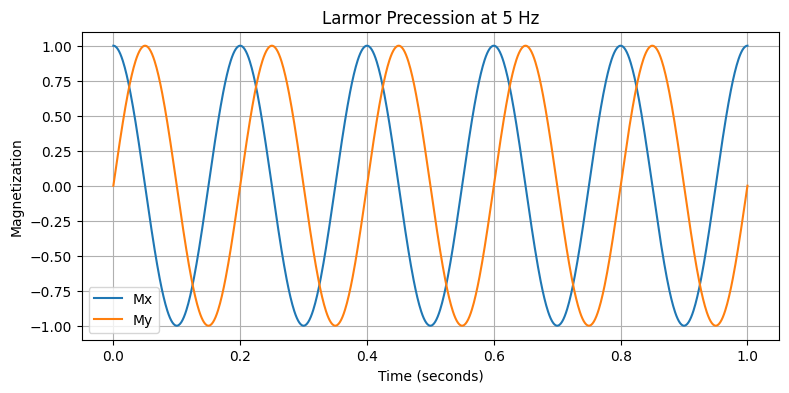

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Rotation frequency: 5 cycles per second
f = 5

# Time from 0 to 1 second
time = np.linspace(0, 1, 1000)

# Angle changes with time
theta = 2 * np.pi * f * time

# Magnetization components
Mx = np.cos(theta)
My = np.sin(theta)

# Plot
plt.figure(figsize=(9, 4))

plt.plot(time, Mx, label="Mx")
plt.plot(time, My, label="My")

plt.xlabel("Time (seconds)")
plt.ylabel("Magnetization")
plt.title("Larmor Precession at 5 Hz")
plt.legend()
plt.grid(True)
plt.show()

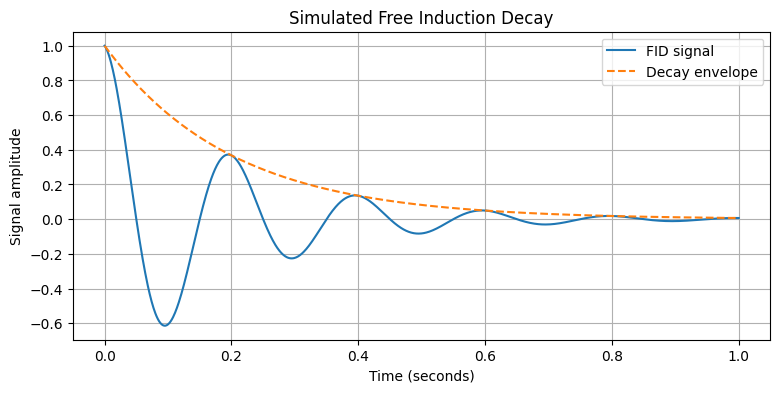

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Set the signal parameters
M0 = 1.0
f = 5
T2_star = 0.2

# 2. Create time points
time = np.linspace(0, 1, 1000)

# 3. Calculate exponential decay
decay = np.exp(-time / T2_star)

# 4. Calculate the FID signal
fid = M0 * decay * np.cos(2 * np.pi * f * time)

# 5. Plot the result
plt.figure(figsize=(9, 4))

plt.plot(time, fid, label="FID signal")
plt.plot(time, decay, "--", label="Decay envelope")

plt.xlabel("Time (seconds)")
plt.ylabel("Signal amplitude")
plt.title("Simulated Free Induction Decay")
plt.legend()
plt.grid(True)
plt.show()

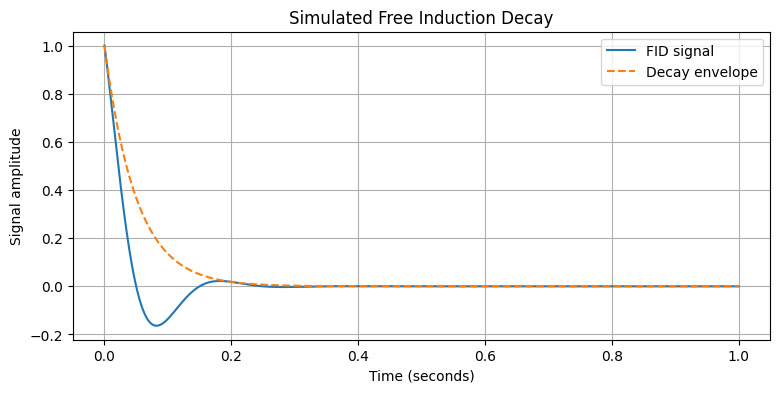

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Set the signal parameters
M0 = 1.0
f = 5
T2_star = 0.05

# 2. Create time points
time = np.linspace(0, 1, 1000)

# 3. Calculate exponential decay
decay = np.exp(-time / T2_star)

# 4. Calculate the FID signal
fid = M0 * decay * np.cos(2 * np.pi * f * time)

# 5. Plot the result
plt.figure(figsize=(9, 4))

plt.plot(time, fid, label="FID signal")
plt.plot(time, decay, "--", label="Decay envelope")

plt.xlabel("Time (seconds)")
plt.ylabel("Signal amplitude")
plt.title("Simulated Free Induction Decay")
plt.legend()
plt.grid(True)
plt.show()

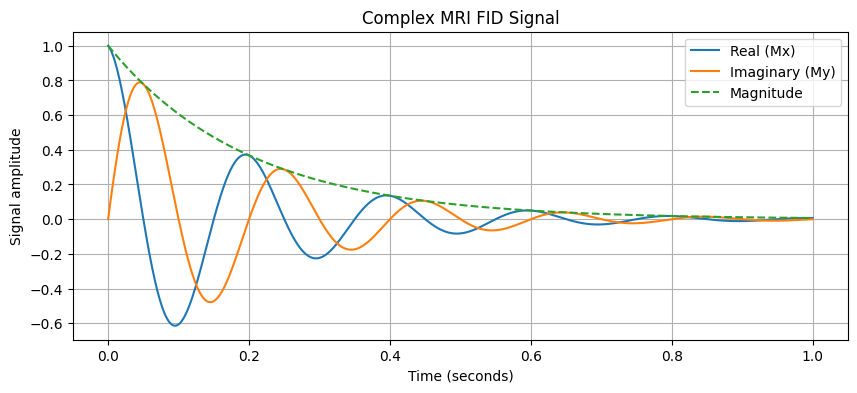

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Step 1: Set parameters
M0 = 1.0
f = 5
T2_star = 0.2

# Step 2: Create time points
time = np.linspace(0, 1, 1000)

# Step 3: Calculate signal decay
decay = np.exp(-time / T2_star)

# Step 4: Calculate both magnetization components
Mx = M0 * decay * np.cos(2 * np.pi * f * time)
My = M0 * decay * np.sin(2 * np.pi * f * time)

# Step 5: Combine into a complex signal
signal = Mx + 1j * My

# Step 6: Plot the components
plt.figure(figsize=(10, 4))

plt.plot(time, signal.real, label="Real (Mx)")
plt.plot(time, signal.imag, label="Imaginary (My)")
plt.plot(time, np.abs(signal), "--", label="Magnitude")

plt.xlabel("Time (seconds)")
plt.ylabel("Signal amplitude")
plt.title("Complex MRI FID Signal")
plt.legend()
plt.grid(True)
plt.show()

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Step 1: Create our simulated MRI signal
M0 = 1.0
f = 5
T2_star = 0.2

N = 1000
dt = 0.001

time = np.arange(N) * dt

signal = (
    M0
    * np.exp(-time / T2_star)
    * np.exp(1j * 2 * np.pi * f * time)
)

# Step 2: Calculate the Fourier Transform
spectrum = np.fft.fft(signal)

# Step 3: Calculate the frequency values
frequencies = np.fft.fftfreq(N, d=dt)

# Step 4: Find the strongest frequency
peak_index = np.argmax(np.abs(spectrum))
peak_frequency = frequencies[peak_index]

print("Detected frequency:", peak_frequency, "Hz")

Detected frequency: 5.0 Hz


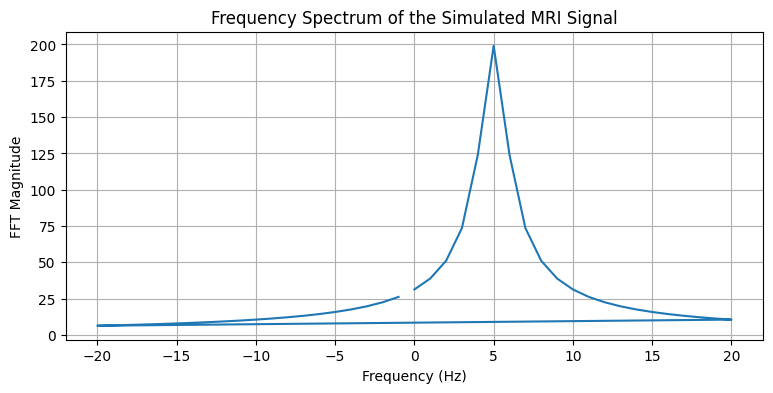

In [6]:
# Keep only frequencies between -20 and 20 Hz
mask = (frequencies >= -20) & (frequencies <= 20)

plt.figure(figsize=(9, 4))

plt.plot(
    frequencies[mask],
    np.abs(spectrum[mask])
)

plt.xlabel("Frequency (Hz)")
plt.ylabel("FFT Magnitude")
plt.title("Frequency Spectrum of the Simulated MRI Signal")
plt.grid(True)
plt.show()